# 4 · Firm-level panel: trade credit and intangible assets (Compustat Global design)
**Research question (from my PhD work).** Do firms with more **intangible assets** extend more **trade credit** to customers, after controlling for size, payables, inventory, cash, profitability, growth, age and country income? The sample design is about 3,600 listed firms in 24 OIC countries, 1999-2021, from Compustat Global.

**About the data.** Compustat is licensed and **cannot be redistributed**, even in modified form. This notebook therefore runs the full pipeline on a **simulated panel** with the same structure and the same data problems as the real extract (`effpanel.synthetic`), with coefficients that are *known by construction*. That makes it a test: a pipeline that recovers the planted truth can be trusted on the real data. To run it on real data, extract with [`scripts/compustat_global_extract.py`](../scripts/compustat_global_extract.py) (WRDS licence needed) and point the same cells at `data/private/oic_firms.csv`.

| Variable | Definition |
|---|---|
| `d1tc` | trade credit supplied = receivables / sales (dependent) |
| `x1intan` | intangible assets / total assets |
| `x2size` | ln(total assets) |
| `x3pay` | accounts payable / total assets (trade credit received) |
| `x4inv`, `x5chf` | inventory / assets, cash / assets |
| `x6profit`, `x7growth`, `x8age` | operating ROA, sales growth, ln(1 + age) |

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 4); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
from effpanel import synthetic, panel
raw = synthetic.simulate(n_firms=3600, seed=0)     # real data: raw = pd.read_csv("../data/private/oic_firms.csv")
print(f"{len(raw):,} firm-years, {raw.firm.nunique():,} firms, {raw.country.nunique()} countries, {raw.year.min()}-{raw.year.max()}")
raw.describe().T[["mean", "50%", "min", "max"]]

41,797 firm-years, 3,600 firms, 24 countries, 1999-2021


,mean,50%,min,max
year,2012.3710,2013.0000,1999.0000,2021.0000
d1tc,0.2907,0.2915,0.0000,0.6976
x1intan,0.0322,0.0304,0.0000,0.1383
x2size,6.7445,6.7411,-0.7953,13.3495
x3pay,0.9254,0.1401,0.0000,9033.1123
x4inv,0.2001,0.2001,0.0000,0.5730
x5chf,0.0827,0.0801,0.0000,0.3111
x6profit,0.0501,0.0504,-0.2475,0.3812
x7growth,12.0622,0.0810,-1.0225,164543.8995
x8age,2.6560,2.7112,1.3134,3.7189


## Cleaning, as in the original research workflow
1. drop duplicated firm-years; 2. keep 2000-2019; 3. drop rows with missing regressors; 4. **winsorise** every ratio at the 1st and 99th percentiles **within each year**, which tames the ratio explosions created by tiny denominators without deleting firms.

In [2]:
xs = list(synthetic.TRUE)
audit = [("raw", len(raw))]
d = raw.drop_duplicates(["firm", "year"]); audit.append(("after removing duplicate firm-years", len(d)))
d = d[d.year.between(2000, 2019)]; audit.append(("after keeping 2000-2019", len(d)))
d = d.dropna(subset=["d1tc"] + xs); audit.append(("after dropping missing values", len(d)))
def winsor(s, q=0.01):
    lo, hi = s.quantile([q, 1 - q]); return s.clip(lo, hi)
clean = d.copy()
for c in ["d1tc"] + xs:
    clean[c] = clean.groupby("year")[c].transform(winsor)
print(pd.DataFrame(audit, columns=["step", "rows"]).to_string(index=False))
pd.DataFrame({"max before": d[["x3pay", "x7growth"]].max(), "max after": clean[["x3pay", "x7growth"]].max()}).round(2)

                               step  rows
                                raw 41797
after removing duplicate firm-years 41383
            after keeping 2000-2019 37215
      after dropping missing values 36467


,max before,max after
x3pay,9033.11,0.31
x7growth,164543.90,0.76


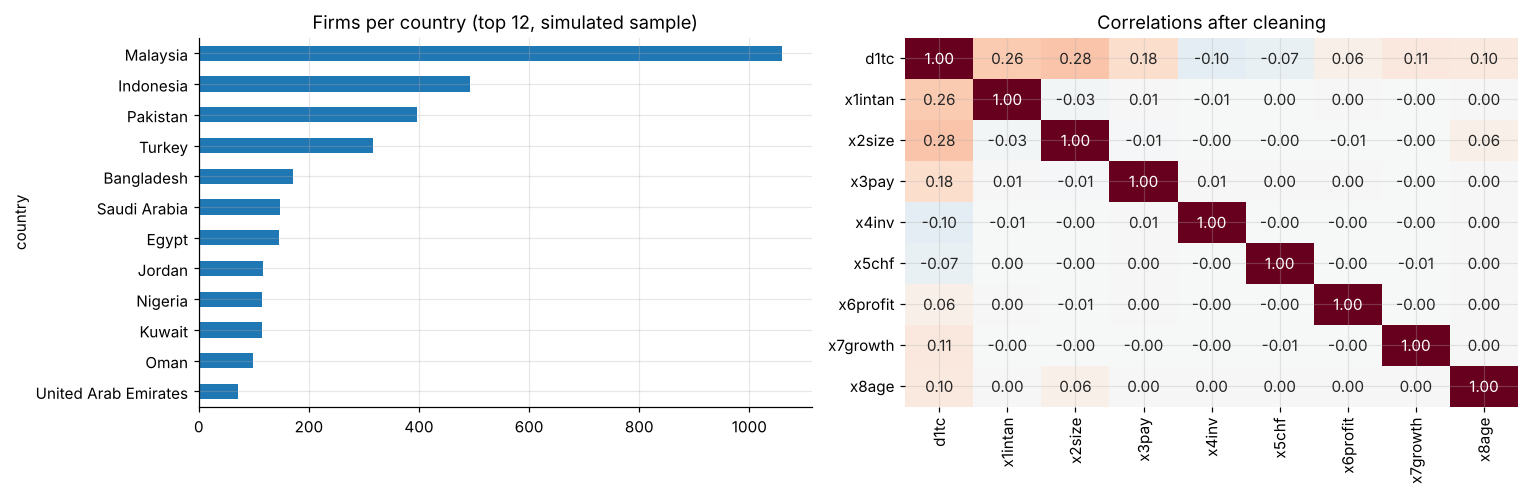

,firms,firm_years,trade_credit,intangibles
country,,,,
Malaysia,1060,10582,0.284,0.028
Indonesia,492,4829,0.297,0.031
Pakistan,397,4031,0.286,0.031
Turkey,317,3266,0.250,0.032
Bangladesh,172,1792,0.337,0.031
Saudi Arabia,148,1525,0.314,0.032
Egypt,145,1436,0.267,0.026
Jordan,117,1213,0.312,0.033


In [3]:
tab = clean.groupby("country").agg(firms=("firm", "nunique"), firm_years=("firm", "size"), trade_credit=("d1tc", "median"), intangibles=("x1intan", "median")).sort_values("firms", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
tab["firms"].head(12).plot.barh(ax=axes[0], title="Firms per country (top 12, simulated sample)"); axes[0].invert_yaxis()
sns.heatmap(clean[["d1tc"] + xs].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1], cbar=False)
axes[1].set_title("Correlations after cleaning")
plt.tight_layout(); plt.savefig(IMG / "firm_panel_overview.png", bbox_inches="tight"); plt.show()
tab.head(8).round(3)

## Estimation: pooled OLS, fixed effects, random effects
Standard errors are clustered by firm. In this design intangibles are **correlated with the unobserved firm effect** (firms with distinctive intangible assets also have distinctive credit policies), so pooled OLS and RE are biased and the within (FE) estimator is consistent. The robust Mundlak-Hausman test should detect this.

In [4]:
P = clean.set_index(["firm", "year"])
res = panel.fit_all(P, "d1tc", xs)
display(panel.comparison_table(res))
h = panel.hausman(P, "d1tc", xs); lm = panel.breusch_pagan_lm(P, "d1tc", xs)
print(f"robust Hausman chi2({h['dof']}) = {h['chi2']:.1f}, p = {h['p_value']:.4f} -> {h['preferred']}")
print("Breusch-Pagan LM:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in lm.items()})

,Pooled OLS,Fixed effects (entity),Fixed effects (two-way),Random effects
Dep. Variable,d1tc,d1tc,d1tc,d1tc
Estimator,PooledOLS,PanelOLS,PanelOLS,RandomEffects
No. Observations,36467,36467,36467,36467
Cov. Est.,Clustered,Clustered,Clustered,Clustered
R-squared,0.2215,0.1928,0.1840,0.2321
R-Squared (Within),0.1457,0.1928,0.1919,0.1917
R-Squared (Between),0.2579,0.1720,0.1714,0.1917
R-Squared (Overall),0.2215,0.1752,0.1746,0.1883
F-statistic,1296.9,981.05,925.91,1080.8
P-value (F-stat),0.0000,0.0000,0.0000,0.0000


robust Hausman chi2(8) = 430.0, p = 0.0000 -> Fixed effects
Breusch-Pagan LM: {'LM': 93260.635, 'p_value': 0.0}


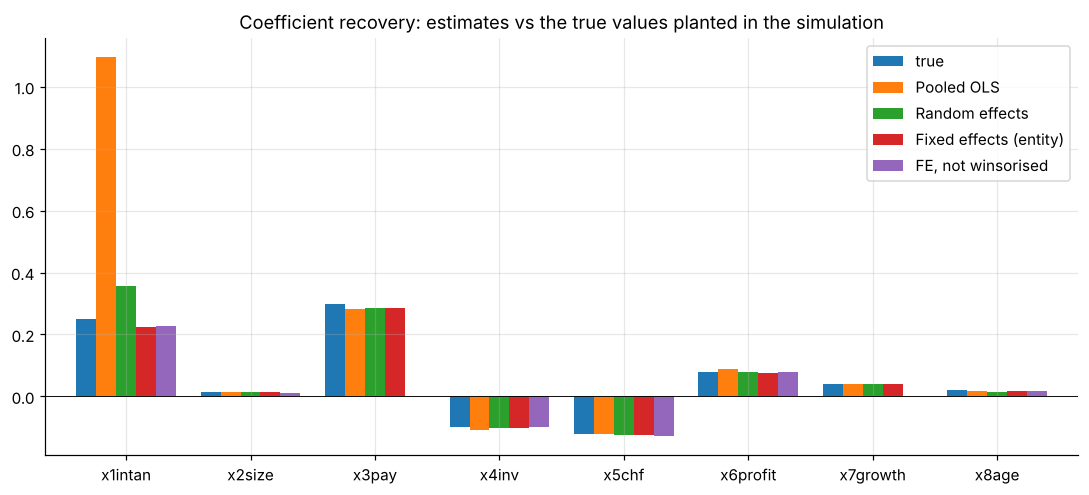

,true,Pooled OLS,Random effects,Fixed effects (entity),Fixed effects (two-way),FE error,"FE, not winsorised"
x1intan,0.250,1.097,0.355,0.223,0.219,-0.027,0.229
x2size,0.015,0.015,0.015,0.014,0.014,-0.001,0.012
x3pay,0.300,0.283,0.284,0.284,0.284,-0.016,-0.000
x4inv,-0.100,-0.109,-0.101,-0.101,-0.101,-0.001,-0.100
x5chf,-0.120,-0.120,-0.125,-0.126,-0.126,-0.006,-0.127
x6profit,0.080,0.087,0.078,0.077,0.077,-0.003,0.078
x7growth,0.040,0.041,0.040,0.040,0.040,-0.000,0.000
x8age,0.020,0.016,0.016,0.016,0.021,-0.004,0.017


In [5]:
rec = pd.DataFrame({"true": synthetic.TRUE})
for k in ["Pooled OLS", "Random effects", "Fixed effects (entity)", "Fixed effects (two-way)"]:
    rec[k] = res[k].params[xs]
rec["FE error"] = rec["Fixed effects (entity)"] - rec["true"]
# what happens without winsorising?
dirty = d.set_index(["firm", "year"])
rec["FE, not winsorised"] = panel.fit_all(dirty, "d1tc", xs)["Fixed effects (entity)"].params[xs]
fig, ax = plt.subplots(figsize=(10, 4.6))
rec[["true", "Pooled OLS", "Random effects", "Fixed effects (entity)", "FE, not winsorised"]].plot.bar(ax=ax, rot=0, width=0.8)
ax.axhline(0, c="k", lw=.6); ax.set_title("Coefficient recovery: estimates vs the true values planted in the simulation")
plt.tight_layout(); plt.savefig(IMG / "firm_panel_recovery.png", bbox_inches="tight"); plt.show()
rec.round(3)

## Findings
* **Cleaning matters.** The simulated extract has duplicated firm-years, missing profitability and ratio explosions: sales growth in the thousands and payables at hundreds of times assets. Winsorising within each year removes the explosions without dropping firms. Without it, the payables and growth coefficients are pulled towards zero because a few extreme values dominate the variance.
* **Model choice matters.** Pooled OLS and random effects overstate the intangibles effect, because intangibility is correlated with the unobserved firm effect. Fixed effects recover the planted coefficient (0.25) closely. The robust Hausman test rejects RE decisively, so the pipeline picks the right estimator for the right reason.
* **How to read this:** these numbers validate the *method*, not an empirical claim about OIC firms. The substantive results come from re-running the same notebook on the licensed Compustat Global extract (see `scripts/compustat_global_extract.py`), which stays private.